Mening promtim:biz hozir ikkita data set dan malumot olib uni, tahlil qilamiz, data cleaning uchun va keyin ai model traning ga : data set - Telco customer churn(iBM), maqsad qaysi customer lar companiyani tark etadi va ularni qanday saqlab qolsa boladi, qaysi xato bisnes uchun yomonroq va nega, classification yoki regressionmi, va target uchun qaysi column tanlanadi.
Data set columnlari: customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
AI javobi: 🎯 Maqsad
Bizning dataset:
customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn

Maqsad: Churn ustunini (Yes/No) bashorat qilish — ya’ni mijoz kompaniyani tark etadimi yoki yo‘qmi.

🧹 Data Cleaning
TotalCharges: ba’zi bo‘sh qiymatlar bo‘lishi mumkin, ularni tozalash yoki to‘ldirish kerak.

Categorical columns: gender, InternetService, Contract, PaymentMethod kabi ustunlarni one-hot encoding qilish.

Numerical columns: tenure, MonthlyCharges, TotalCharges ni scaling/normalizatsiya qilish.

ID column: customerID — model uchun foydasiz, uni olib tashlash kerak.

📊 Classification yoki Regression?
Regression → sonli qiymatlarni bashorat qilish uchun.

Classification → kategorik natija (Yes/No).

Bu datasetda Churn ustuni Yes/No bo‘lgani uchun Classification muammo.

🎯 Target Column
Target: Churn (Yes/No).

Model shu ustunni bashorat qiladi.

⚠️ Qaysi xato biznes uchun yomonroq?
False Negative (FN): Model mijoz ketmaydi deb o‘ylaydi, lekin u aslida ketadi.
👉 Bu eng xavfli, chunki kompaniya hech qanday choralar ko‘rmaydi va mijozni yo‘qotadi.

False Positive (FP): Model mijoz ketadi deb o‘ylaydi, lekin u aslida qoladi.
👉 Bu ham xarajat keltiradi (masalan, chegirma berish), lekin mijoz qoladi, zarar FN ga qaraganda kichikroq.

Xulosa: Biznes uchun eng yomon xato — False Negative.

📌 Xulosa
Model turi: Classification (binary).

Target column: Churn.

Eng yomon xato: False Negative (mijoz ketadi, lekin model uni qoladi deb o‘ylaydi).

Data cleaning: customerID ni olib tashlash, TotalCharges ni tozalash, kategorik ustunlarni encoding qilish, raqamli ustunlarni scaling qilish.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.info()
df.head(3).T

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


In [ ]:
# 1) Yo'qolgan qiymatlar va bo'sh matnlar
print(df.isna().sum().sum())
print((df.apply(lambda c: c.astype(str).str.strip() == "")).sum()[lambda s: s > 0])


0
TotalCharges    11
dtype: int64


In [ ]:
# 2) TotalCharges ichidagi matnli qatorlar
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(tc.isna().sum())
print(df.loc[tc.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])


11
      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


In [ ]:
# 3) Dublikatlar (customerID'siz)
print(df.drop(columns="customerID").duplicated().sum())

22


In [ ]:
# 4) Target balansi
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
# 5) Har bir kategorik ustundagi noyob qiymatlar
for c in df.select_dtypes("object").columns.drop(["customerID", "TotalCharges"]):
    print(c, df[c].nunique(), df[c].unique().tolist())

gender 2 ['Female', 'Male']
Partner 2 ['Yes', 'No']
Dependents 2 ['No', 'Yes']
PhoneService 2 ['No', 'Yes']
MultipleLines 3 ['No phone service', 'No', 'Yes']
InternetService 3 ['DSL', 'Fiber optic', 'No']
OnlineSecurity 3 ['No', 'Yes', 'No internet service']
OnlineBackup 3 ['Yes', 'No', 'No internet service']
DeviceProtection 3 ['No', 'Yes', 'No internet service']
TechSupport 3 ['No', 'Yes', 'No internet service']
StreamingTV 3 ['No', 'Yes', 'No internet service']
StreamingMovies 3 ['No', 'Yes', 'No internet service']
Contract 3 ['Month-to-month', 'One year', 'Two year']
PaperlessBilling 2 ['Yes', 'No']
PaymentMethod 4 ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn 2 ['No', 'Yes']


In [ ]:
# 6) Numerik ustunlar
df_num = df[["tenure", "MonthlyCharges"]].assign(TotalCharges=tc)
print(df_num.describe().T[["min", "max", "mean", "50%"]])
print(df_num.skew())

                  min      max         mean       50%
tenure           0.00    72.00    32.371149    29.000
MonthlyCharges  18.25   118.75    64.761692    70.350
TotalCharges    18.80  8684.80  2283.300441  1397.475
tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.961642
dtype: float64


In [ ]:
cols = df.columns.drop("customerID")
dups = df[df.duplicated(subset=cols, keep=False)].sort_values(list(cols))
print(dups[["customerID", "tenure", "MonthlyCharges", "Churn"]].head(10))
print(dups["Churn"].value_counts())

      customerID  tenure  MonthlyCharges Churn
6491  9728-FTTVZ       1           69.20   Yes
6764  7660-HDPJV       1           69.20   Yes
4495  4702-IOQDC       1           70.10   Yes
6267  0328-GRPMV       1           70.10   Yes
5522  2619-WFQWU       1           70.15   Yes
5759  9985-MWVIX       1           70.15   Yes
542   2866-IKBTM       1           19.55    No
1491  8605-ITULD       1           19.55    No
5170  7721-DVEKZ       1           19.65    No
6774  0970-QXPXW       1           19.65    No
Churn
Yes    24
No     18
Name: count, dtype: int64


Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn01, dtype: float64


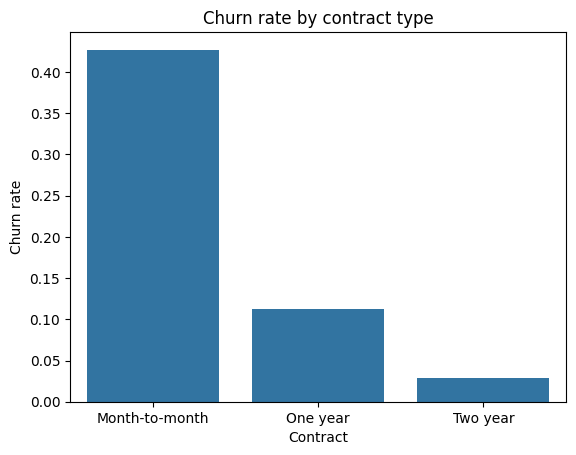

In [ ]:
eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")
eda["Churn01"] = (eda["Churn"] == "Yes").astype(int)

# 1) Contract bo'yicha churn
order = ["Month-to-month", "One year", "Two year"]
print((eda.groupby("Contract")["Churn01"].mean() * 100).round(1))
sns.barplot(data=eda, x="Contract", y="Churn01", order=order, errorbar=None)
plt.title("Churn rate by contract type"); plt.ylabel("Churn rate"); plt.show()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


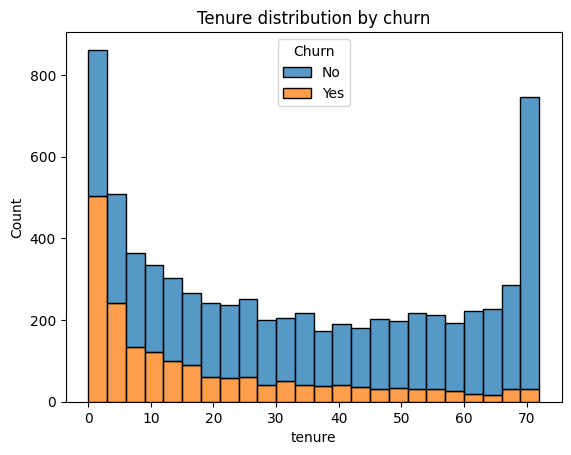

In [ ]:
# 2) Tenure va churn
print(eda.groupby("Churn")["tenure"].median())
sns.histplot(data=eda, x="tenure", hue="Churn", bins=24, multiple="stack")
plt.title("Tenure distribution by churn"); plt.show()


Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


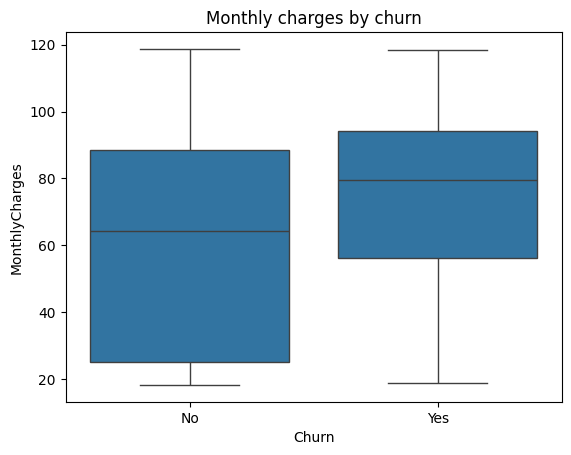

In [ ]:
# 3) MonthlyCharges va churn
print(eda.groupby("Churn")["MonthlyCharges"].median())
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges by churn"); plt.show()


InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn01, dtype: float64


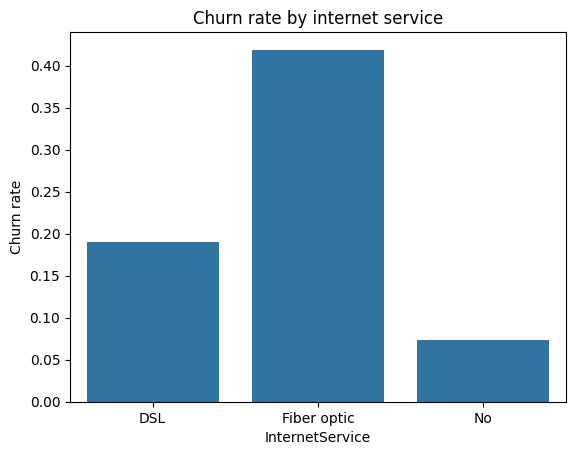

In [ ]:
# 4) InternetService bo'yicha churn
print((eda.groupby("InternetService")["Churn01"].mean() * 100).round(1))
sns.barplot(data=eda, x="InternetService", y="Churn01", errorbar=None)
plt.title("Churn rate by internet service"); plt.ylabel("Churn rate"); plt.show()


PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn01, dtype: float64


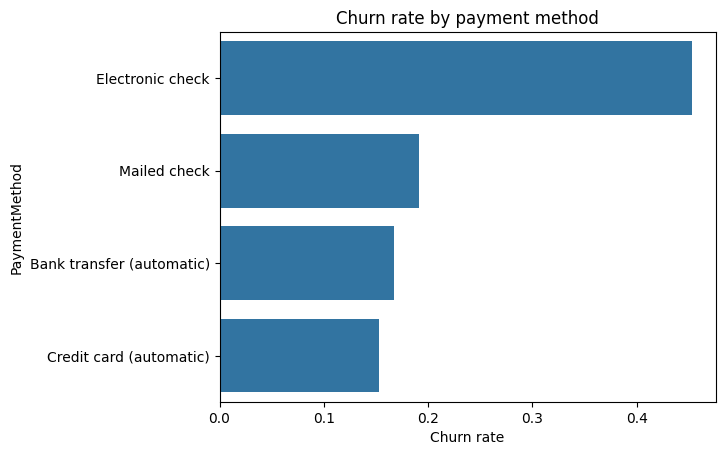

In [ ]:
# 5) PaymentMethod bo'yicha churn
print((eda.groupby("PaymentMethod")["Churn01"].mean() * 100).round(1))
sns.barplot(data=eda, y="PaymentMethod", x="Churn01", errorbar=None)
plt.title("Churn rate by payment method"); plt.xlabel("Churn rate"); plt.show()


In [ ]:
# Outlier tekshiruvi (IQR)
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    s = eda[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
    print(c, "outliers:", n)

tenure outliers: 0
MonthlyCharges outliers: 0
TotalCharges outliers: 0


In [ ]:
# 1) customerID: noyobligini tekshirib, so'ng olib tashlash
print(df["customerID"].is_unique)
df_clean = df.drop(columns="customerID").copy()

True


In [ ]:
# 2) TotalCharges: matn -> son
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
print(df_clean["TotalCharges"].isna().sum())   # 11 bo'lishi kerak

# 2-usul A: 11 qatorni o'chirish
df_drop = df_clean.dropna(subset=["TotalCharges"]).copy()

# 2-usul B: 0 bilan to'ldirish
df_fill = df_clean.copy()
df_fill["TotalCharges"] = df_fill["TotalCharges"].fillna(0)

# Taqqoslash
for name, d in [("drop", df_drop), ("fill0", df_fill)]:
    print(name, d.shape, round((d["Churn"] == "Yes").mean() * 100, 2),
          round(d["TotalCharges"].mean(), 2))


11
drop (7032, 20) 26.58 2283.3
fill0 (7043, 20) 26.54 2279.73


In [ ]:
# 3) Dublikatlar: o'chirmaymiz, faqat hisobga olamiz
print("Dublikatlar:", df_fill.duplicated().sum())

Dublikatlar: 22


In [ ]:
# 4) Target -> 0/1
df_fill["Churn"] = df_fill["Churn"].map({"No": 0, "Yes": 1})
print(df_fill["Churn"].value_counts())


Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
# 5) Yakuniy tekshiruv
df_final = df_fill
print(df_final.shape)
print(df_final.isna().sum().sum())
print(df_final.dtypes.value_counts())

(7043, 20)
0
object     15
int64       3
float64     2
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

cat_cols = df_final.select_dtypes("object").columns.tolist()
print(len(cat_cols), cat_cols)          # 15 bo'lishi kerak

# Version A: One-Hot
A = pd.get_dummies(df_final, columns=cat_cols, drop_first=True, dtype=int)

# Version B: Ordinal / Label
B = df_final.copy()
B["Contract"] = B["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
B["gender"] = B["gender"].map({"Female": 0, "Male": 1})
for c in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
    B[c] = B[c].map({"No": 0, "Yes": 1})

rest = [c for c in cat_cols if c not in
        ["Contract", "gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]]
B[rest] = OrdinalEncoder().fit_transform(B[rest]).astype(int)

print("A:", A.shape, " B:", B.shape)
print(A.dtypes.value_counts()); print(B.dtypes.value_counts())
print(A.isna().sum().sum(), B.isna().sum().sum())

15 ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
A: (7043, 31)  B: (7043, 20)
int64      29
float64     2
Name: count, dtype: int64
int64      18
float64     2
Name: count, dtype: int64
0 0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]   # faqat haqiqiy numerik
scalers = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

def split(D):
    X, y = D.drop(columns="Churn"), D["Churn"]
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

data = {}   # kalit: (versiya, scaler) -> (X_train, X_test, y_train, y_test)
for ver, D in [("A", A), ("B", B)]:
    Xtr, Xte, ytr, yte = split(D)
    data[(ver, "none")] = (Xtr.copy(), Xte.copy(), ytr, yte)
    for sname, S in scalers.items():
        sc = S()
        Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
        Xtr_s[num_cols] = sc.fit_transform(Xtr[num_cols])   # fit: faqat train
        Xte_s[num_cols] = sc.transform(Xte[num_cols])       # test: faqat transform
        data[(ver, sname)] = (Xtr_s, Xte_s, ytr, yte)

# Tekshiruvlar
Xtr, Xte, ytr, yte = data[("A", "none")]
print(Xtr.shape, Xte.shape)
print(ytr.mean().round(4), yte.mean().round(4))     # ikkalasi ~0.2654 bo'lishi kerak
print((data[("A","none")][3].index == data[("B","none")][3].index).all())  # A va B bir xil split

# Scaling'dan oldin va keyin (A versiya, train)
before = data[("A", "none")][0][num_cols].agg(["min", "max", "mean", "std"]).T
print("none\n", before.round(3))
for s in scalers:
    print(s, "\n", data[("A", s)][0][num_cols].agg(["min", "max", "mean", "std"]).T.round(3))

(5634, 30) (1409, 30)
0.2654 0.2654
True
none
                  min      max      mean       std
tenure           0.0    72.00    32.485    24.569
MonthlyCharges  18.4   118.75    64.930    30.138
TotalCharges     0.0  8684.80  2299.335  2279.204
standard 
                   min    max  mean  std
tenure         -1.322  1.608  -0.0  1.0
MonthlyCharges -1.544  1.786  -0.0  1.0
TotalCharges   -1.009  2.802   0.0  1.0
minmax 
                 min  max   mean    std
tenure          0.0  1.0  0.451  0.341
MonthlyCharges  0.0  1.0  0.464  0.300
TotalCharges    0.0  1.0  0.265  0.262
robust 
                   min    max   mean    std
tenure         -0.630  0.935  0.076  0.534
MonthlyCharges -0.959  0.888 -0.103  0.555
TotalCharges   -0.406  2.124  0.263  0.664


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

models = {
    "LogReg": lambda: LogisticRegression(max_iter=1000, random_state=42),
    "KNN": lambda: KNeighborsClassifier(),
    "RandomForest": lambda: RandomForestClassifier(random_state=42),
}

rows = []
for (ver, sname), (Xtr, Xte, ytr, yte) in data.items():
    for mname, make in models.items():
        m = make().fit(Xtr, ytr)
        p = m.predict(Xte)
        rows.append({
            "model": mname,
            "encoding": "OneHot" if ver == "A" else "Ordinal",
            "scaler": sname,
            "accuracy": accuracy_score(yte, p),
            "F1": f1_score(yte, p),
            "recall": recall_score(yte, p),
        })

results = pd.DataFrame(rows).sort_values("recall", ascending=False).reset_index(drop=True)
print(len(results))            # 24 bo'lishi kerak
print(results.round(4).to_string())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

24
           model encoding    scaler  accuracy      F1  recall
0         LogReg   OneHot  standard    0.8062  0.6049  0.5588
1         LogReg   OneHot      none    0.8048  0.6020  0.5561
2         LogReg  Ordinal      none    0.7991  0.5940  0.5535
3         LogReg   OneHot    robust    0.8041  0.6000  0.5535
4            KNN   OneHot  standard    0.7630  0.5523  0.5508
5         LogReg  Ordinal  standard    0.7999  0.5925  0.5481
6         LogReg   OneHot    minmax    0.7991  0.5916  0.5481
7            KNN   OneHot    robust    0.7551  0.5418  0.5455
8         LogReg  Ordinal    robust    0.7984  0.5884  0.5428
9         LogReg  Ordinal    minmax    0.7991  0.5893  0.5428
10           KNN   OneHot    minmax    0.7480  0.5286  0.5321
11           KNN  Ordinal  standard    0.7594  0.5324  0.5160
12           KNN  Ordinal    minmax    0.7473  0.5189  0.5134
13  RandomForest  Ordinal  standard    0.7942  0.5685  0.5107
14  RandomForest  Ordinal    robust    0.7935  0.5676  0.5107
15  R

In [ ]:
# Bonus: class imbalance
Xtr, Xte, ytr, yte = data[("A", "standard")]
for name, m in {
    "LogReg": LogisticRegression(max_iter=1000, random_state=42),
    "LogReg balanced": LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
    "RF": RandomForestClassifier(random_state=42),
    "RF balanced": RandomForestClassifier(random_state=42, class_weight="balanced"),
}.items():
    p = m.fit(Xtr, ytr).predict(Xte)
    print(f"{name:16} acc={accuracy_score(yte,p):.4f} F1={f1_score(yte,p):.4f} recall={recall_score(yte,p):.4f}")

# Top omillar: yakuniy model koeffitsientlari
final = LogisticRegression(max_iter=1000, random_state=42).fit(Xtr, ytr)
coef = pd.Series(final.coef_[0], index=Xtr.columns).sort_values()
print(coef.head(8).round(3)); print(coef.tail(8).round(3))
print(pd.Series(coef.abs().sort_values(ascending=False).head(10).round(3)))

# Random Forest importance (taqqoslash uchun)
rf = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
print(pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False).head(10).round(3))

LogReg           acc=0.8062 F1=0.6049 recall=0.5588
LogReg balanced  acc=0.7381 F1=0.6136 recall=0.7834
RF               acc=0.7850 F1=0.5498 recall=0.4947
RF balanced      acc=0.7899 F1=0.5542 recall=0.4920
Contract_Two year                -1.314
tenure                           -1.257
Contract_One year                -0.684
PhoneService_Yes                 -0.521
MonthlyCharges                   -0.467
OnlineSecurity_Yes               -0.349
TechSupport_Yes                  -0.299
MultipleLines_No phone service   -0.269
dtype: float64
SeniorCitizen                     0.148
MultipleLines_Yes                 0.362
StreamingMovies_Yes               0.373
PaperlessBilling_Yes              0.374
StreamingTV_Yes                   0.375
PaymentMethod_Electronic check    0.393
TotalCharges                      0.528
InternetService_Fiber optic       1.181
dtype: float64
Contract_Two year                 1.314
tenure                            1.257
InternetService_Fiber optic       1.181
Co